# 01 — EDA et manifest du dataset dentaire

**Auteur :** Maxime Gouleme  |  **Dataset :** Kaggle Oral Image Dataset (6 classes)

## Pourquoi ce notebook existe
Observation de départ : le dataset contient **déjà des copies modifiées des mêmes photos** (luminosité, etc.) et certaines images sont **deux photos collées** (un côté sain, un côté problématique). Conséquences :

1. Si une photo et sa copie modifiée tombent l'une dans le **train** et l'autre dans le **test**, le modèle est évalué sur une image qu'il connaît déjà : **fuite de données**, scores trop optimistes. Un contrôle de doublons exacts ne les voit pas.
2. Le nombre d'images (4 375) n'est **pas** le nombre de photos indépendantes. C'est la vraie taille du dataset qu'il faut connaître.
3. Les images composites posent une question sur la validité des étiquettes.

## Ce que ce notebook produit
- Les graphiques et chiffres de l'EDA (dans `outputs/eda/`).
- Un fichier **`data/data_manifest.csv`** : une ligne par image avec sa classe, son **groupe de copies** et son **split** (train / val / test). Les notebooks d'entraînement le lisent : toute l'équipe évalue sur **le même test**.
- Un Excel de synthèse (`outputs/eda/eda_summary.xlsx`) pour les slides.

## Comment l'utiliser
1. Colab : **Exécution > Modifier le type d'exécution**. Un GPU n'est pas nécessaire ici (CPU suffit).
2. Exécute dans l'ordre. Deux paramètres sont à **régler en regardant les images** (✋ marqués) : le seuil de copies (section 3.6) et le seuil d'images composites (section 3.4).
3. Les cellules ✍️ sont à écrire **avec tes mots** : c'est ce qui est noté et ce que tu défendras à l'oral.

> Ce code a été généré avec l'aide de Claude. Tu dois pouvoir expliquer chaque cellule sans notes. Note tes vérifications dans ton AI Use Log.

## 1. Mise en place

In [30]:
!pip -q install kagglehub

In [31]:
import io, os, hashlib, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

# ---------- Paramètres ----------
SEED = 42
TEST_FRACTION = 0.15          # visé : ~15 % test (le découpage par groupes donne un résultat approché)
VAL_FRACTION = 0.15           # visé : ~15 % validation
HASH_SIZE = 16                # empreinte visuelle de 16x16 -> 256 bits par image
DUP_THRESHOLD = 48            # ✋ distance (en bits sur 256) sous laquelle deux images sont "la même photo modifiée" : À RÉGLER en 3.6
SEAM_THRESHOLD = 3.0          # ✋ score au-dessus duquel on soupçonne "deux photos collées" : À RÉGLER en 3.4

MANIFEST_PATH = Path("data/data_manifest.csv")
OUT_DIR = Path("outputs/eda")
MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED)

## 2. Les données

### 2.1 Téléchargement
Le dataset est public (CC0) : on le télécharge depuis Kaggle dans Colab. **On ne le met jamais dans GitHub** (473 Mo).

En général le téléchargement marche **sans compte Kaggle**. Si une erreur d'authentification apparaît : crée un compte gratuit sur kaggle.com, génère un token API (*Settings > API*), puis dans Colab (icône 🔑 *Secrets*) ajoute un secret nommé `KAGGLE_API_TOKEN` avec ce token et autorise l'accès au notebook. Autre option : exécuter `kagglehub.login()` et coller le token. Voir `guide_github_colab.md`.

In [32]:
import kagglehub

try:
    DATA_ROOT = Path(kagglehub.dataset_download("jhirshaikh/oral-image-dataset"))
except Exception as e:
    print("Téléchargement impossible :", e)
    print("-> Mets le dataset dans Colab à la main et indique son dossier ci-dessous.")
    DATA_ROOT = Path("/content/oral-image-dataset")   # <-- à adapter si besoin

print("Dataset dans :", DATA_ROOT)

Using Colab cache for faster access to the 'oral-image-dataset' dataset.
Dataset dans : /kaggle/input/oral-image-dataset


### 2.2 Inventaire
Une ligne par image : chemin **relatif** au dossier du dataset (il change à chaque session Colab, le chemin relatif non), classe (= nom du dossier parent), largeur, hauteur.
Les lignes sont **triées** : l'ordre de lecture des dossiers n'est pas garanti, et un ordre différent donnerait un split différent. Trié = reproductible chez tout le monde.

**À vérifier :** 6 classes attendues (Calculus, Caries, Hypodontia, Mouth Ulcer, Normal, Tooth Discoloration).

In [33]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_FOLDERS = {"train", "test", "val", "valid", "validation"}   # dossiers de découpage, pas des classes

rows = []
for p in DATA_ROOT.rglob("*"):
    if p.suffix.lower() in IMG_EXT:
        label = p.parent.name.strip().title()   # normalise la casse : "caries" -> "Caries", "Mouth ulcer" -> "Mouth Ulcer"
        if label.lower() in SPLIT_FOLDERS:
            continue
        with Image.open(p) as im:
            w, h = im.size
        rows.append({"rel_path": p.relative_to(DATA_ROOT).as_posix(), "label": label, "width": w, "height": h})

df = pd.DataFrame(rows).sort_values("rel_path").reset_index(drop=True)
assert len(df) > 0, "Aucune image trouvée : vérifie DATA_ROOT"
df["path"] = df.rel_path.map(lambda r: str(DATA_ROOT / r))
print(f"{len(df)} images, {df.label.nunique()} classes")
print(df.label.value_counts())
if df.label.nunique() != 6:
    print("ATTENTION : on attendait 6 classes. Regarde les noms ci-dessus et la structure des dossiers.")

4375 images, 6 classes
label
Calculus               1296
Hypodontia             1251
Tooth Discoloration    1058
Normal                  286
Mouth Ulcer             265
Caries                  219
Name: count, dtype: int64


## 3. EDA

### 3.1 Combien d'images par classe ?

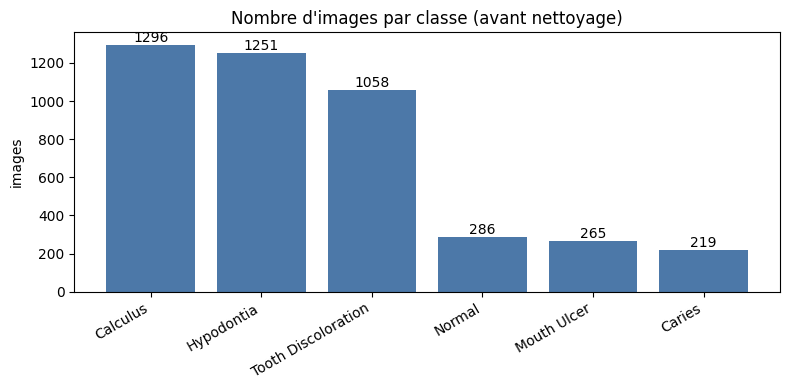

Rapport plus grande / plus petite classe : 5.9x


In [34]:
counts = df.label.value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color="#4C78A8")
ax.bar_label(bars)
ax.set_title("Nombre d'images par classe (avant nettoyage)"); ax.set_ylabel("images")
plt.xticks(rotation=30, ha="right")
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_class_counts.png", dpi=150); plt.show()
print(f"Rapport plus grande / plus petite classe : {counts.max() / counts.min():.1f}x")

### 3.2 Regarder **chaque** classe
5 images au hasard par classe. Regarde en particulier : les copies plus claires ou plus sombres d'une même photo, les images à deux photos, les étiquettes qui te semblent douteuses. **Relance la cellule plusieurs fois** pour voir d'autres images (change `GRID_SEED`).

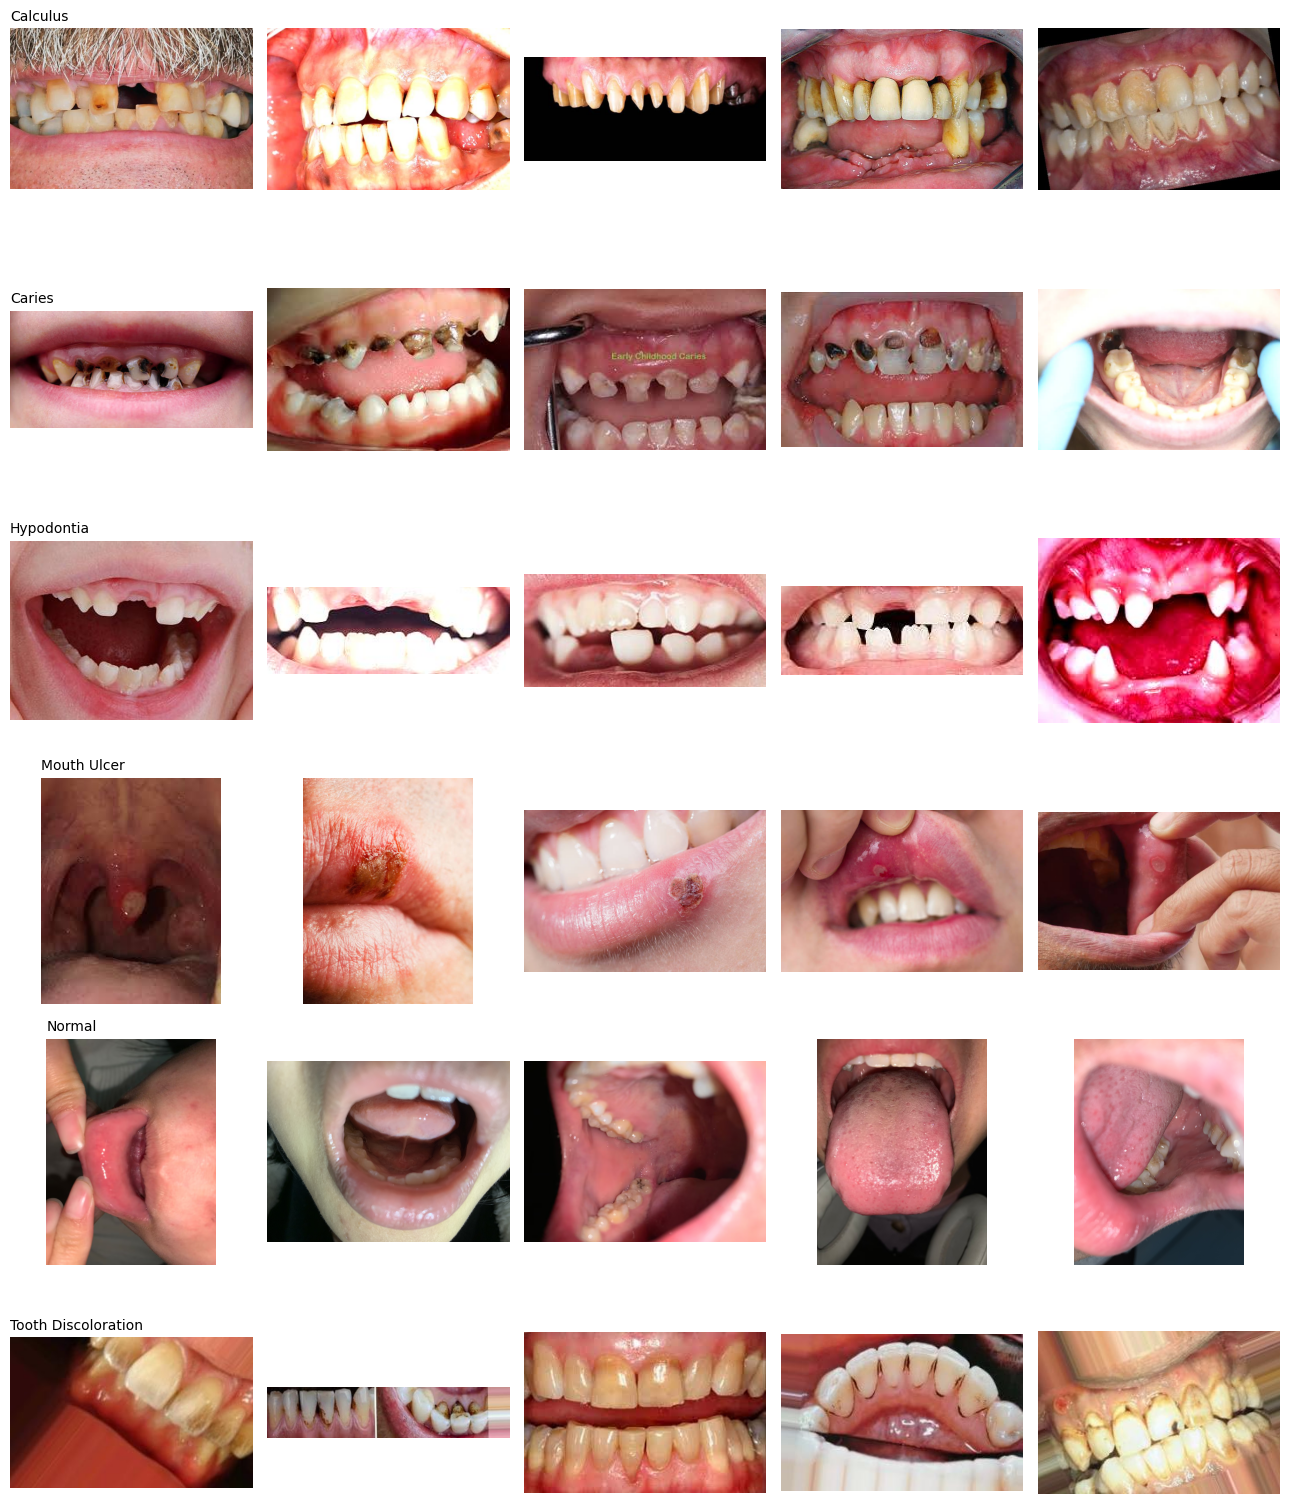

In [35]:
GRID_SEED = 0
classes_sorted = sorted(df.label.unique())
n_show = 5
fig, axes = plt.subplots(len(classes_sorted), n_show, figsize=(2.6 * n_show, 2.6 * len(classes_sorted)))
rng = np.random.RandomState(GRID_SEED)
for r, cls in enumerate(classes_sorted):
    paths = df[df.label == cls].path.tolist()
    for c, p in enumerate(rng.choice(paths, size=min(n_show, len(paths)), replace=False)):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_sample_grid.png", dpi=120); plt.show()

### 3.3 Analyse de **toutes** les images en une passe
Pour chaque image, on calcule en une seule lecture :
- l'empreinte **MD5** (doublons exacts) ;
- la **luminosité** moyenne ;
- le **score de couture** (voir 3.4) ;
- une **empreinte visuelle** (*dHash*) de l'image et de son miroir (voir 3.6).

Compte 2 à 5 minutes (barre de progression).

In [36]:
def dhash_bits(gray, size=HASH_SIZE):
    # Empreinte visuelle : contraste auto (efface les écarts de luminosité), réduction, puis pour chaque pixel
    # "est-il plus clair que son voisin de droite ?" -> size*size bits. Robuste aux changements de luminosité/contraste.
    g = ImageOps.autocontrast(gray).resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()


def seam_score(gray):
    # Une "couture" = frontière verticale nette pile au milieu (deux photos collées côte à côte).
    # Score = contraste entre colonnes voisines au centre / contraste des colonnes proches (6 à 10 colonnes de part et d'autre).
    # Autour de 1-3 : pas de couture. Très au-dessus : pic au centre, donc probable couture.
    g = np.asarray(gray.resize((128, 128)), dtype=np.float32)
    col = np.abs(np.diff(g, axis=1)).mean(axis=0)          # 127 valeurs : contraste entre colonne k et k+1
    centre = col[62:65].max()
    voisines = np.r_[col[52:58], col[67:73]].mean()
    return float(centre / (voisines + 1e-6))


records, H, HF = [], [], []
for p in tqdm(df.path, desc="analyse des images"):
    data = Path(p).read_bytes()
    gray = Image.open(io.BytesIO(data)).convert("L")
    records.append({"md5": hashlib.md5(data).hexdigest(),
                    "brightness": float(np.asarray(gray, dtype=np.float32).mean()),
                    "seam": seam_score(gray)})
    H.append(dhash_bits(gray)); HF.append(dhash_bits(ImageOps.mirror(gray)))

df = pd.concat([df, pd.DataFrame(records)], axis=1)
H, HF = np.array(H), np.array(HF)
print("OK :", len(df), "images analysées")

analyse des images:   0%|          | 0/4375 [00:00<?, ?it/s]

OK : 4375 images analysées


### 3.4 Images à deux photos en une (images « composites »)
Heuristique : le **score de couture** compare le contraste au centre de l'image à celui des colonnes voisines : il est **bien plus élevé** quand il y a une frontière nette pile au milieu. Ce n'est qu'un indice, **pas une preuve** : regarde les images avec les scores les plus hauts, et celles juste en dessous, puis règle `SEAM_THRESHOLD` (en haut) là où la frontière « composite / non composite » te semble correcte.

12 images au score de couture le plus élevé :


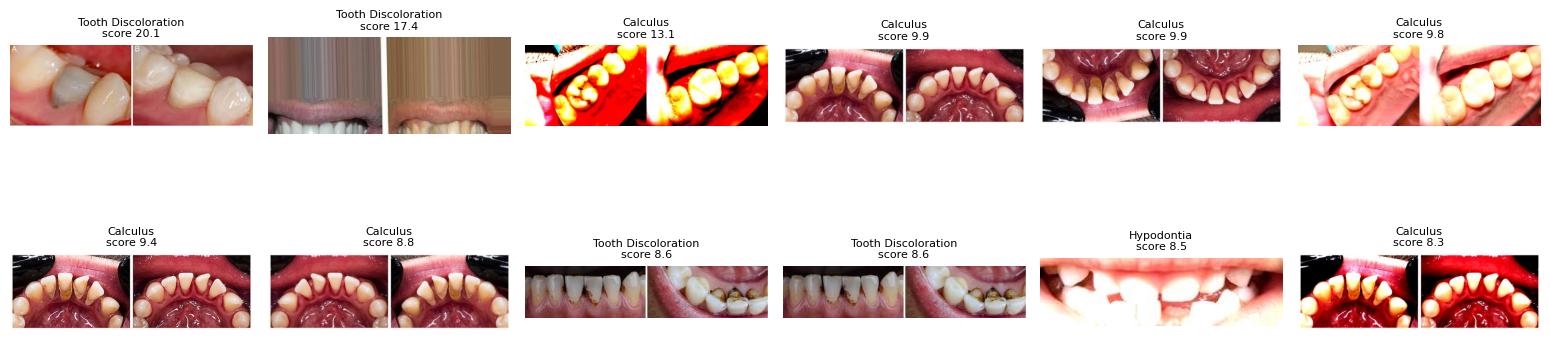

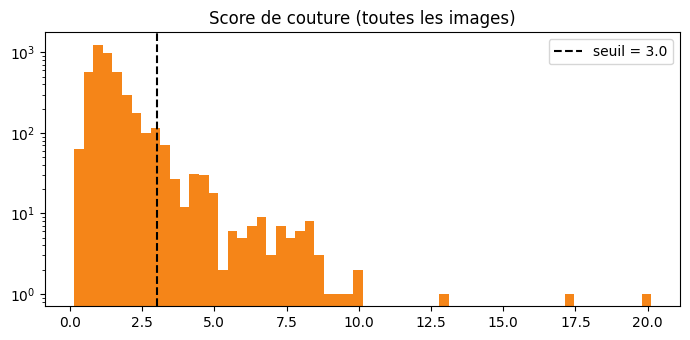

Images soupçonnées composites avec le seuil actuel : 309 sur 4375


,images_composites,part
label,,
Calculus,199,0.154
Caries,1,0.005
Hypodontia,89,0.071
Mouth Ulcer,6,0.023
Normal,1,0.003
Tooth Discoloration,13,0.012


In [37]:
def show_images(paths, titles, ncols=6, size=2.6, save=None):
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for ax, p, t in zip(axes.flatten(), paths, titles):
        ax.imshow(Image.open(p).convert("RGB")); ax.set_title(t, fontsize=8)
    fig.tight_layout()
    if save:
        fig.savefig(OUT_DIR / save, dpi=120)
    plt.show()


top = df.sort_values("seam", ascending=False).head(12)
print("12 images au score de couture le plus élevé :")
show_images(top.path, [f"{r.label}\nscore {r.seam:.1f}" for r in top.itertuples()], save="eda_seam_top.png")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df.seam, bins=60, color="#F58518"); ax.axvline(SEAM_THRESHOLD, color="k", ls="--", label=f"seuil = {SEAM_THRESHOLD}")
ax.set_yscale("log"); ax.set_title("Score de couture (toutes les images)"); ax.legend()
fig.tight_layout(); plt.show()

df["composite"] = df.seam >= SEAM_THRESHOLD
comp = df.groupby("label").composite.agg(images_composites="sum", part="mean").round(3)
print(f"Images soupçonnées composites avec le seuil actuel : {int(df.composite.sum())} sur {len(df)}")
comp

✍️ **Images composites (à écrire toi-même)** :
- Les images à fort score sont-elles vraiment des deux photos collées ? Le seuil te semble-t-il bon ?
- Dans quelles classes en trouve-t-on le plus ?
- Que devient l'étiquette d'une image dont une moitié est saine ? (On garde l'étiquette du dataset, on garde et on le note dans les limites, on exclut ?) **Choisis et justifie** — et note-le dans ta question au tuteur si tu hésites.

_(Ton texte ici.)_

Les images à fort score sont toutes deux photos collées, le seuil semble être bon.

On retrouve le plus dans le dossier calculus et hypodontia.

J'aurais dit qu'on la retire mais je vais demander au prof

### 3.5 Tailles et luminosité
Des images de tailles très différentes sont déformées différemment par le redimensionnement. Si une classe est systématiquement plus sombre, le modèle risque d'apprendre la **luminosité** plutôt que la maladie.

Tailles les plus fréquentes :
width  height
612    408       859
275    183       201
612    407       106
       405        97
259    194        72
300    168        65
612    293        51
       406        46
dtype: int64


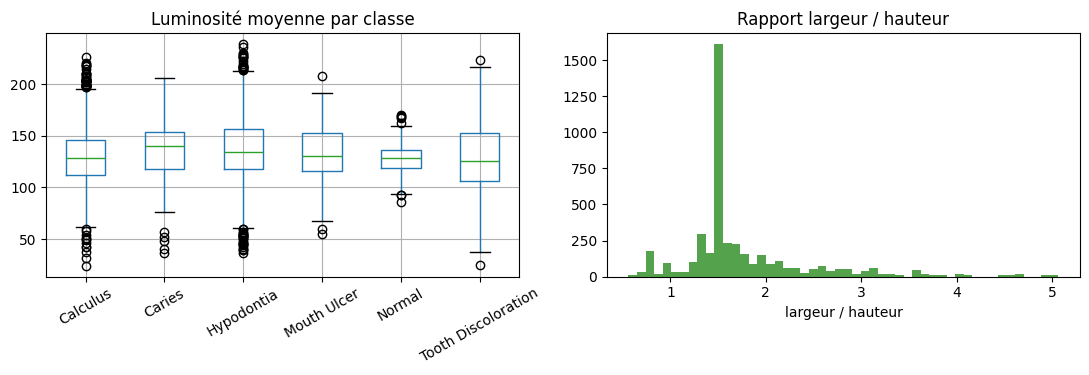

                      width  height  brightness
label                                          
Calculus              611.8   380.7       129.7
Caries                425.2   299.9       135.5
Hypodontia            346.4   184.6       136.4
Mouth Ulcer           321.2   230.9       131.9
Normal               2281.0  2433.1       127.8
Tooth Discoloration   316.2   206.3       128.5


In [38]:
print("Tailles les plus fréquentes :")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(8))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column="brightness", by="label", ax=ax[0], rot=30)
ax[0].set_title("Luminosité moyenne par classe"); ax[0].set_xlabel(""); fig.suptitle("")
ax[1].hist(df.width / df.height, bins=50, color="#54A24B"); ax[1].set_title("Rapport largeur / hauteur"); ax[1].set_xlabel("largeur / hauteur")
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_size_brightness.png", dpi=150); plt.show()
print(df.groupby("label")[["width", "height", "brightness"]].mean().round(1))

### 3.6 Copies modifiées de la même photo (le point critique)
**Principe :** deux images qui sont « la même photo, plus claire / retournée » ont des empreintes visuelles très proches. On calcule, pour chaque paire d'images, une **distance de Hamming** (nombre de bits différents sur 256). On teste aussi la version miroir.

**Comment choisir le seuil** (`DUP_THRESHOLD`) : pour chaque image, on regarde la distance à son voisin le plus proche. Si le dataset contient des copies, l'histogramme montre **deux bosses** : une à gauche (copies) et une à droite (images vraiment différentes). Le seuil se met dans la vallée entre les deux. **Si tu ne vois qu'une seule bosse, il n'y a pas (ou peu) de copies.**

D'abord, on retire les doublons **exacts** (même fichier) et les images **identiques avec des étiquettes différentes** (étiquette contradictoire : on ne peut pas faire confiance).

In [39]:
# Étiquettes contradictoires : même fichier, classes différentes -> on retire toutes ces images
n_labels_per_md5 = df.groupby("md5").label.nunique()
conflict_md5 = set(n_labels_per_md5[n_labels_per_md5 > 1].index)
n_conflict_imgs = int(df.md5.isin(conflict_md5).sum())

keep = ~df.md5.isin(conflict_md5)
# Doublons exacts : on garde la première
keep &= ~df.md5.duplicated(keep="first")
n_exact = int((df.md5.duplicated(keep="first") & ~df.md5.isin(conflict_md5)).sum())

print(f"Images à étiquette contradictoire retirées : {n_conflict_imgs}")
print(f"Doublons exacts retirés                    : {n_exact}")

df = df[keep.values].reset_index(drop=True)
H, HF = H[keep.values], HF[keep.values]
print(f"Images restantes : {len(df)}")

Images à étiquette contradictoire retirées : 121
Doublons exacts retirés                    : 459
Images restantes : 3795


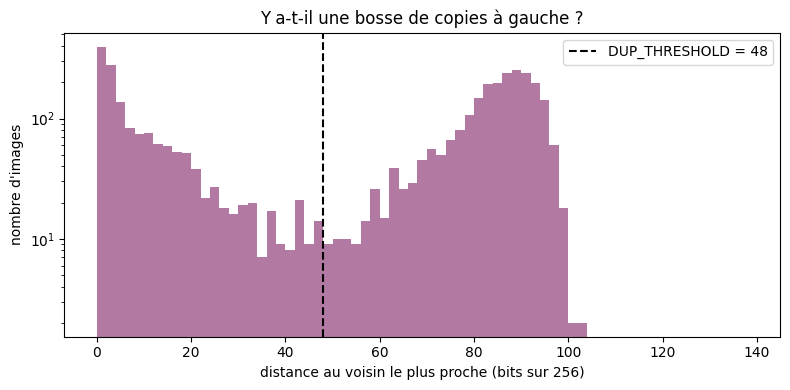

Images dont le voisin le plus proche est à moins de 48 bits : 1520 sur 3795


In [40]:
def hamming_matrix(A, B):
    A = A.astype(np.float32); B = B.astype(np.float32)
    return A @ (1 - B).T + (1 - A) @ B.T          # nombre de bits différents pour chaque paire

# distance entre i et j = la plus petite entre (i,j) et (i, miroir de j)
D = np.minimum(hamming_matrix(H, H), hamming_matrix(H, HF))
np.fill_diagonal(D, np.inf)
nn_dist = D.min(axis=1)                            # distance au voisin le plus proche de chaque image

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(nn_dist, bins=np.arange(0, 140, 2), color="#B279A2")
ax.axvline(DUP_THRESHOLD, color="k", ls="--", label=f"DUP_THRESHOLD = {DUP_THRESHOLD}")
ax.set_yscale("log"); ax.set_xlabel("distance au voisin le plus proche (bits sur 256)"); ax.set_ylabel("nombre d'images")
ax.set_title("Y a-t-il une bosse de copies à gauche ?"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_near_duplicates_hist.png", dpi=150); plt.show()

print(f"Images dont le voisin le plus proche est à moins de {DUP_THRESHOLD} bits : "
      f"{int((nn_dist <= DUP_THRESHOLD).sum())} sur {len(df)}")

✋ **Règle `DUP_THRESHOLD` maintenant** : regarde l'histogramme, mets le seuil dans la vallée, **relance la cellule précédente**, puis regarde ci-dessous si les groupes trouvés sont bien « la même photo modifiée ».

In [41]:
# Sensibilité au seuil : à quel point le nombre de groupes dépend-il du seuil ?
# Lecture : on cherche un PALIER (le nombre de groupes bouge peu) AVANT que le plus gros groupe n'explose
# (un plus gros groupe qui bondit = des images différentes se retrouvent reliées en chaîne : seuil trop haut).
rows = []
for t in range(10, 85, 5):
    n_g, g_id = connected_components(csr_matrix(D <= t), directed=False)
    sz = np.bincount(g_id)
    rows.append({"seuil": t, "groupes": n_g, "plus gros groupe": int(sz.max()),
                 "% images dans un groupe >= 2": round(100 * (sz[g_id] >= 2).mean(), 1)})
sensitivity = pd.DataFrame(rows)
print(sensitivity.to_string(index=False))

 seuil  groupes  plus gros groupe  % images dans un groupe >= 2
    10     3023                 7                          27.1
    15     2870                 7                          31.2
    20     2753                 8                          34.3
    25     2693                12                          35.9
    30     2655                12                          37.0
    35     2623                12                          38.0
    40     2600                12                          38.8
    45     2572                22                          39.6
    50     2548                53                          40.4
    55     2526                69                          41.0
    60     2484                83                          42.3
    65     2412                89                          44.3
    70     2298               112                          47.1
    75     2103               359                          51.5
    80     1745              1258       

In [42]:
# Groupes de copies : deux images sont reliées si leur distance <= seuil ; un groupe = ensemble d'images reliées
n_groups, group_id = connected_components(csr_matrix(D <= DUP_THRESHOLD), directed=False)
df["group_id"] = group_id
sizes = df.group_id.value_counts()

print(f"{len(df)} images -> {n_groups} groupes (≈ nombre de photos originales indépendantes)")
print(f"Images appartenant à un groupe de 2 images ou plus : {int((df.group_id.map(sizes) >= 2).sum())} "
      f"({(df.group_id.map(sizes) >= 2).mean():.0%})")
print("Taille du plus gros groupe :", int(sizes.max()))
print(pd.cut(sizes, [0, 1, 2, 5, 10, 10_000], labels=["1", "2", "3-5", "6-10", ">10"]).value_counts().sort_index().rename("nb de groupes par taille"))

label_conflict = df.groupby("group_id").label.nunique()
print(f"Groupes contenant plusieurs classes différentes : {int((label_conflict > 1).sum())}")

3795 images -> 2556 groupes (≈ nombre de photos originales indépendantes)
Images appartenant à un groupe de 2 images ou plus : 1522 (40%)
Taille du plus gros groupe : 52
count
1       2273
2         56
3-5       12
6-10     212
>10        3
Name: nb de groupes par taille, dtype: int64
Groupes contenant plusieurs classes différentes : 4


Groupe 16 : 52 images


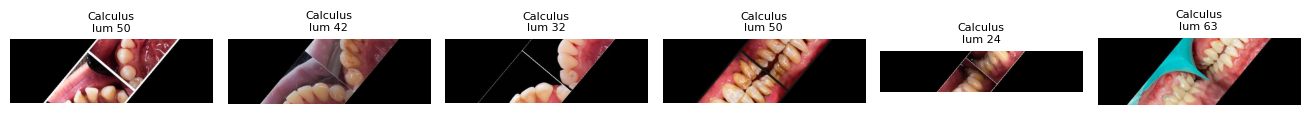

Groupe 516 : 12 images


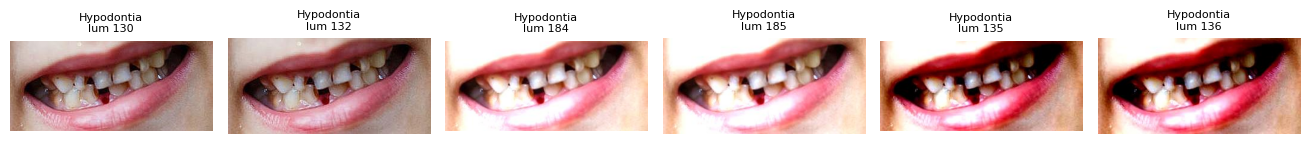

Groupe 498 : 12 images


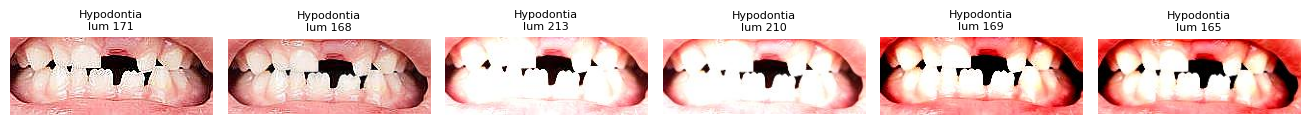

Paires proches du seuil (gauche/droite) :


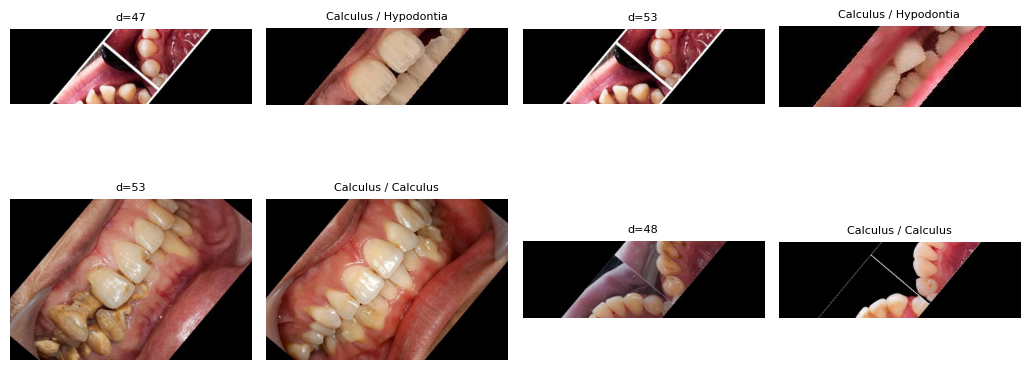

In [43]:
# Regarder les 3 plus gros groupes (6 images max chacun) : sont-ce bien des copies de la même photo ?
for gid in sizes.head(3).index:
    g = df[df.group_id == gid].head(6)
    print(f"Groupe {gid} : {sizes[gid]} images")
    show_images(g.path, [f"{r.label}\nlum {r.brightness:.0f}" for r in g.itertuples()], ncols=6, size=2.2)

# Paires proches du seuil : c'est là que l'on se trompe le plus, donc là qu'il faut regarder
border = np.argwhere(np.triu((D > DUP_THRESHOLD - 6) & (D <= DUP_THRESHOLD + 6)))[:4]
if len(border):
    print("Paires proches du seuil (gauche/droite) :")
    paths, titles = [], []
    for i, j in border:
        paths += [df.path[i], df.path[j]]; titles += [f"d={D[i, j]:.0f}", f"{df.label[i]} / {df.label[j]}"]
    show_images(paths, titles, ncols=4, size=2.6)

✍️ **Copies modifiées (à écrire toi-même, c'est la découverte clé de l'EDA)** :
- Y a-t-il une bosse à gauche dans l'histogramme ? Quel seuil as-tu choisi et comment l'as-tu justifié ?
- Les groupes affichés sont-ils bien des copies de la même photo ? Des paires proches du seuil te font-elles douter ?
- **Combien de photos indépendantes** reste-t-il (nombre de groupes) par rapport aux images ? Par classe ? (tableau ci-dessous)
- Que ce soit pour le modèle (risque de fuite) ou pour la taille réelle du dataset, qu'est-ce que cela change ?

_(Ton texte ici.)_

Il y a bien une bosse à gauche dans l'historigramme, j'ai modifié le seuil à 48 pour qu'il soit plus dans le creux.

En ce qui concerne les groupe parfois c'est des photos qui se ressemble mais sont différentes et parfois c'est la meme photo mais modifé avec les jeux de lumière.

In [44]:
indep = pd.DataFrame({
    "images": df.groupby("label").size(),
    "groupes (≈ photos indépendantes)": df.groupby("label").group_id.nunique(),
})
indep["images par groupe"] = (indep.images / indep["groupes (≈ photos indépendantes)"]).round(1)
indep

,images,groupes (≈ photos indépendantes),images par groupe
label,,,
Calculus,802,349,2.3
Caries,194,180,1.1
Hypodontia,1224,492,2.5
Mouth Ulcer,243,220,1.1
Normal,284,282,1.0
Tooth Discoloration,1048,1037,1.0


## 4. Découpage train / validation / test **par groupes**

| Jeu | Rôle |
|---|---|
| **Train** (~70 %) | le modèle apprend dessus |
| **Validation** (~15 %) | on choisit dessus (learning rate, meilleur modèle) |
| **Test** (~15 %) | note finale, **utilisé une seule fois** |

**Par groupes** : toutes les copies d'une même photo vont dans **le même jeu**. C'est ce qui supprime la fuite. **Stratifié** : chaque jeu garde à peu près les mêmes proportions de classes. Les proportions obtenues sont approchées (on déplace des groupes entiers, pas des images isolées).

In [45]:
classes = sorted(df.label.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["y"] = df.label.map(class_to_idx)

# 1) on met de côté le test (~1/7 des groupes), 2) dans le reste on met de côté la validation (~1/6)
n_test_folds = round(1 / TEST_FRACTION)
sg1 = StratifiedGroupKFold(n_splits=n_test_folds, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(sg1.split(df, df.y, df.group_id))

trainval = df.iloc[trainval_idx]
n_val_folds = round(1 / (VAL_FRACTION / (1 - TEST_FRACTION)))
sg2 = StratifiedGroupKFold(n_splits=n_val_folds, shuffle=True, random_state=SEED)
train_i, val_i = next(sg2.split(trainval, trainval.y, trainval.group_id))

df["split"] = "train"
df.loc[trainval.index[val_i], "split"] = "val"
df.loc[df.index[test_idx], "split"] = "test"

# Contrôle clé : aucun groupe n'est partagé entre deux jeux
assert df.groupby("group_id").split.nunique().max() == 1, "Un groupe est coupé entre deux jeux !"
print("OK : aucun groupe de copies n'est partagé entre train, val et test.")

split_img = pd.crosstab(df.label, df.split)[["train", "val", "test"]]
split_img.loc["TOTAL"] = split_img.sum()
print("\nImages par jeu :"); print(split_img)
print("\nProportions :", (df.split.value_counts(normalize=True)[["train", "val", "test"]] * 100).round(1).to_dict(), "(%)")
split_groups = pd.crosstab(df.drop_duplicates("group_id").label, df.drop_duplicates("group_id").split)[["train", "val", "test"]]
print("\nGroupes (photos indépendantes) par jeu :"); print(split_groups)

OK : aucun groupe de copies n'est partagé entre train, val et test.

Images par jeu :
split                train  val  test
label                                
Calculus               598  100   104
Caries                 138   30    26
Hypodontia             884  172   168
Mouth Ulcer            174   33    36
Normal                 203   42    39
Tooth Discoloration    747  150   151
TOTAL                 2744  527   524

Proportions : {'train': 72.3, 'val': 13.9, 'test': 13.8} (%)

Groupes (photos indépendantes) par jeu :
split                train  val  test
label                                
Calculus               259   44    46
Caries                 128   27    25
Hypodontia             354   69    68
Mouth Ulcer            158   30    32
Normal                 201   42    39
Tooth Discoloration    737  147   150


### 4.1 Audit de fuite : les images les plus proches entre test et train
Le découpage par groupes garantit qu'aucune paire sous le seuil n'est partagée entre deux jeux. Mais si le seuil est **trop bas**, une copie qui s'est échappée de son groupe peut se retrouver de l'autre côté. Pour le vérifier, on regarde les paires **test / train les plus proches** : si elles ressemblent à « la même photo », le seuil est trop bas : **remonte `DUP_THRESHOLD` et relance depuis la section 3.6**.

Distance minimale test -> train : 49 bits | validation -> train : 50 bits (seuil de copies : 48)
Images de test dont le plus proche voisin de train est à moins de 63 bits : 30 sur 524
Les 4 paires test/train les plus proches (test à gauche, train à droite) :


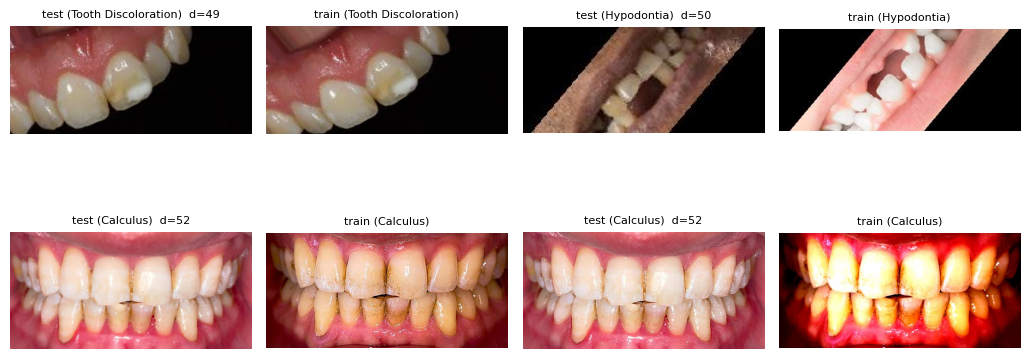

In [46]:
is_tr, is_va, is_te = (df.split == "train").values, (df.split == "val").values, (df.split == "test").values
d_test_train = D[np.ix_(is_te, is_tr)].min(axis=1)       # pour chaque image de test : distance à l'image de train la plus proche
d_val_train = D[np.ix_(is_va, is_tr)].min(axis=1)
print(f"Distance minimale test -> train : {d_test_train.min():.0f} bits | validation -> train : {d_val_train.min():.0f} bits (seuil de copies : {DUP_THRESHOLD})")
print(f"Images de test dont le plus proche voisin de train est à moins de {DUP_THRESHOLD + 15} bits : {int((d_test_train <= DUP_THRESHOLD + 15).sum())} sur {is_te.sum()}")

te_pos, tr_pos = np.where(is_te)[0], np.where(is_tr)[0]
closest = np.argsort(d_test_train)[:4]
paths, titles = [], []
for c in closest:
    i = te_pos[c]; j = tr_pos[D[i, tr_pos].argmin()]
    paths += [df.path[i], df.path[j]]; titles += [f"test ({df.label[i]})  d={d_test_train[c]:.0f}", f"train ({df.label[j]})"]
print("Les 4 paires test/train les plus proches (test à gauche, train à droite) :")
show_images(paths, titles, ncols=4, size=2.6)

✍️ **Découpage (à écrire toi-même)** : les trois jeux ont-ils des proportions de classes proches ? La petite classe (Caries) est-elle présente dans le test en quantité suffisante pour que son score ait un sens ? Que veut dire un test avec très peu de groupes pour une classe ? Les paires test/train les plus proches de l'audit 4.1 sont-elles différentes ?

_(Ton texte ici.)_

Oui les photos sont proches sauf pour la deuxième paire, elles sont différentes de l'audit 4.1.

## 5. Enregistrer le manifest et la synthèse Excel

Le **manifest** est le fichier qui fait le lien entre le dataset (non versionné) et le code : chemin relatif, classe, groupe, split. Il pèse quelques centaines de Ko : on le **commit dans GitHub**. Ton coéquipier n'a qu'à le lire pour avoir **exactement le même split** que toi.

In [47]:
manifest_cols = ["rel_path", "label", "y", "split", "group_id", "md5", "width", "height", "brightness", "seam", "composite"]
df[manifest_cols].to_csv(MANIFEST_PATH, index=False)
print(f"Manifest enregistré : {MANIFEST_PATH}  ({len(df)} lignes)")

# Synthèse Excel (utile pour les slides)
summary = {
    "images_par_classe": df.label.value_counts().rename_axis("classe").reset_index(name="images"),
    "photos_independantes": indep.reset_index().rename(columns={"label": "classe"}),
    "split_images": split_img.reset_index().rename(columns={"label": "classe"}),
    "split_groupes": split_groups.reset_index().rename(columns={"label": "classe"}),
    "composites_par_classe": comp.reset_index().rename(columns={"label": "classe"}),
    "nettoyage": pd.DataFrame({
        "etape": ["étiquette contradictoire", "doublons exacts", "groupes de copies", "images finales"],
        "valeur": [n_conflict_imgs, n_exact, int(n_groups), len(df)]}),
}
with pd.ExcelWriter(OUT_DIR / "eda_summary.xlsx") as xw:
    for name, t in summary.items():
        t.to_excel(xw, sheet_name=name, index=False)
print("Synthèse Excel :", OUT_DIR / "eda_summary.xlsx")

Manifest enregistré : data/data_manifest.csv  (3795 lignes)
Synthèse Excel : outputs/eda/eda_summary.xlsx


## 6. Checklist avant de continuer
- [ ] J'ai regardé des images de **chaque** classe (pas seulement la première)
- [ ] J'ai réglé `DUP_THRESHOLD` en regardant l'histogramme **et** les groupes
- [ ] J'ai réglé `SEAM_THRESHOLD` en regardant les images composites
- [ ] Les 5 cellules ✍️ sont écrites avec mes mots
- [ ] `data/data_manifest.csv` est **commité dans GitHub** (par une seule personne : les autres vérifient qu'ils obtiennent le même fichier)
- [ ] Mon AI Use Log est à jour